# Función de consumo en EE. UU. (1959–2009): regresión simple y sus límites

**Autora:** María de la Luz Flores Porras · Lic. en Economía y Desarrollo Sustentable, UAT

**Pregunta:** ¿cuánto del ingreso disponible adicional se destina al consumo (propensión marginal a consumir, PMC)? ¿Qué tan confiable es una regresión simple para estimarla con series de tiempo?

**Datos:** serie trimestral `macrodata` incluida en la librería *statsmodels* (datos macroeconómicos reales de EE. UU., 1959-T1 a 2009-T3; miles de millones de dólares de 2005).

**Variables:** `realcons` (consumo personal real) y `realdpi` (ingreso personal disponible real).

In [1]:
import numpy as np, pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt
from statsmodels.stats.stattools import durbin_watson

df = sm.datasets.macrodata.load_pandas().data
df['fecha'] = pd.PeriodIndex([f'{int(y)}Q{int(q)}' for y, q in zip(df.year, df.quarter)], freq='Q')
df = df[['fecha','realcons','realdpi']].dropna()
df.describe().round(1)

,realcons,realdpi
count,203.0,203.0
mean,4825.3,5310.5
std,2313.3,2423.5
min,1707.4,1886.9
25%,2874.1,3277.0
50%,4299.9,4959.4
75%,6398.2,6977.8
max,9363.6,10077.5


## 1. Exploración: ¿qué relación hay entre consumo e ingreso?

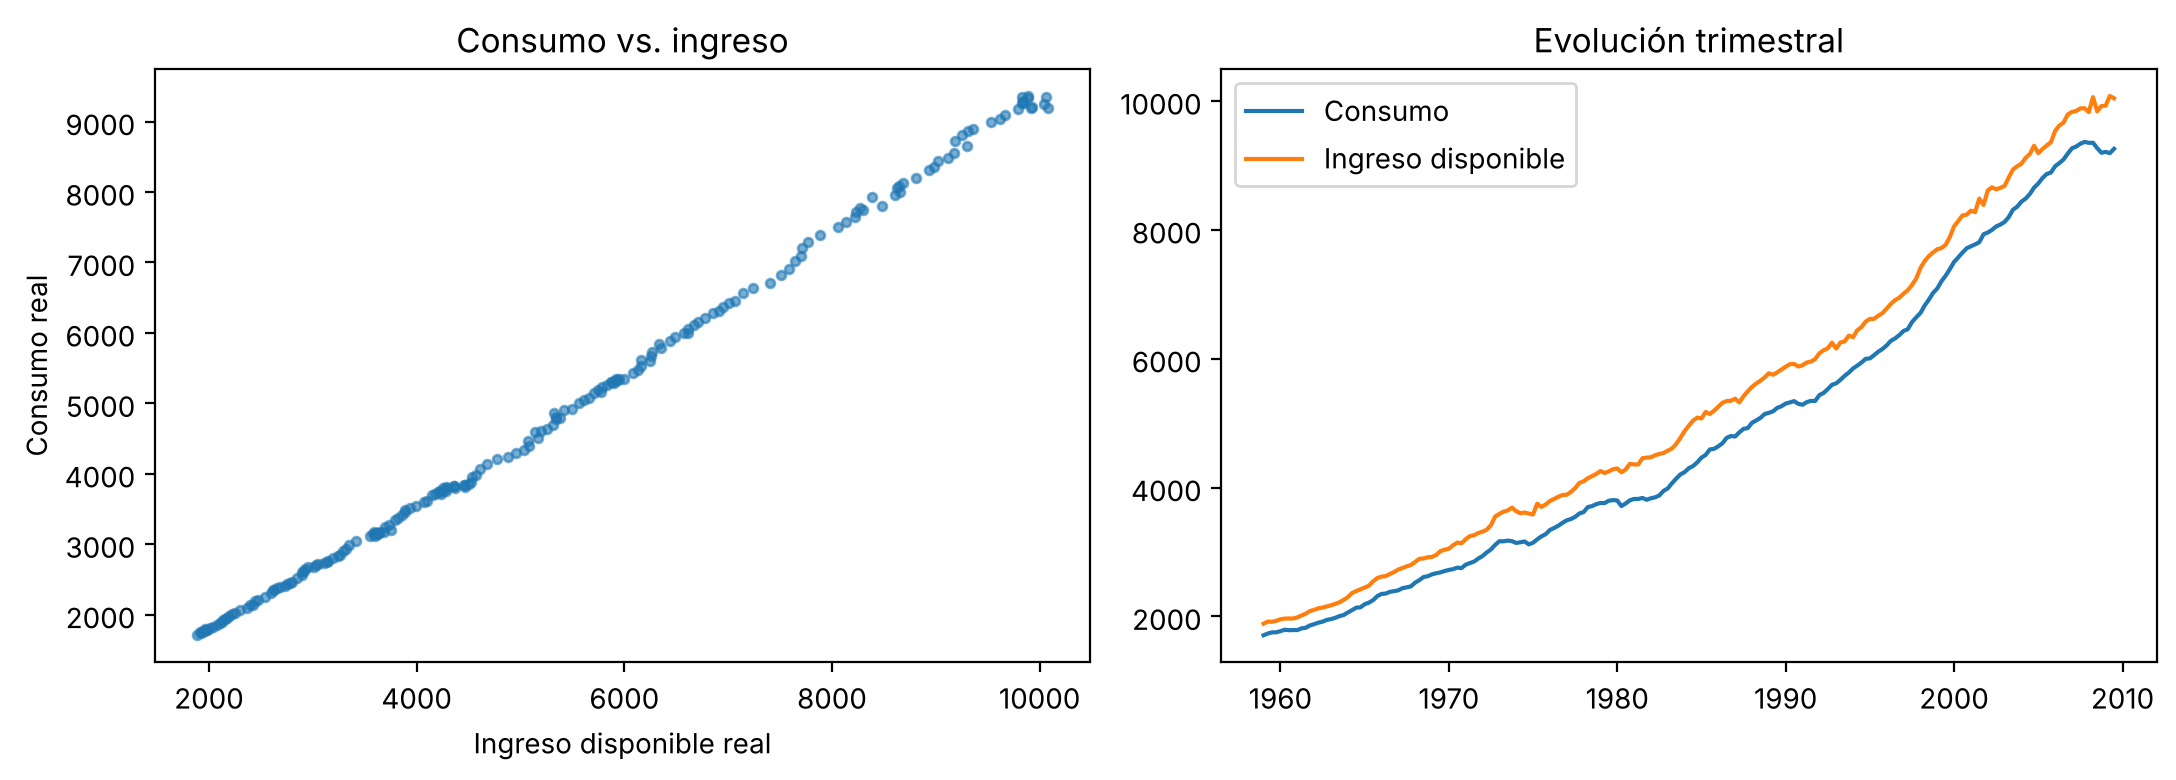

In [2]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].scatter(df.realdpi, df.realcons, s=10, alpha=.6)
ax[0].set_xlabel('Ingreso disponible real'); ax[0].set_ylabel('Consumo real'); ax[0].set_title('Consumo vs. ingreso')
ax[1].plot(df.fecha.dt.to_timestamp(), df.realcons, label='Consumo')
ax[1].plot(df.fecha.dt.to_timestamp(), df.realdpi, label='Ingreso disponible')
ax[1].legend(); ax[1].set_title('Evolución trimestral')
plt.tight_layout(); plt.savefig('figura_consumo_ingreso.png', dpi=130); plt.show()

## 2. Regresión simple en niveles: $C_t = \\beta_0 + \\beta_1 Y_t + u_t$

In [3]:
X = sm.add_constant(df.realdpi); m1 = sm.OLS(df.realcons, X).fit()
print(m1.summary().tables[1]); print('R2 =', round(m1.rsquared, 4), '| Durbin-Watson =', round(durbin_watson(m1.resid), 3))

                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       -239.2308     16.745    -14.287      0.000    -272.249    -206.212
realdpi        0.9537      0.003    332.315      0.000       0.948       0.959
R2 = 0.9982 | Durbin-Watson = 0.253


**Lectura:** la pendiente es la PMC (cuánto sube el consumo por cada dólar adicional de ingreso). El $R^2$ es altísimo, pero el estadístico Durbin-Watson es muy bajo (cercano a 0.25, cuando lo ideal es cerca de 2): los residuos están fuertemente autocorrelacionados. Eso es una señal de alerta.

## 3. Modelo log-log: elasticidad consumo-ingreso

In [4]:
m2 = sm.OLS(np.log(df.realcons), sm.add_constant(np.log(df.realdpi))).fit()
print(m2.summary().tables[1]); print('Elasticidad =', round(m2.params.iloc[1], 3), '| DW =', round(durbin_watson(m2.resid), 3))

                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         -0.3758      0.025    -15.053      0.000      -0.425      -0.327
realdpi        1.0320      0.003    350.545      0.000       1.026       1.038
Elasticidad = 1.032 | DW = 0.188


## 4. Diagnóstico: ¿regresión espuria?
Ambas series crecen con el tiempo (tienden a ser no estacionarias), así que una regresión en niveles puede dar un ajuste alto sin que la relación sea confiable. Una forma sencilla de comprobarlo es estimar la relación en **primeras diferencias** (cambios de un trimestre a otro).

In [5]:
d = np.log(df[['realcons','realdpi']]).diff().dropna()
m3 = sm.OLS(d.realcons, sm.add_constant(d.realdpi)).fit()
print(m3.summary().tables[1]); print('R2 =', round(m3.rsquared, 4), '| DW =', round(durbin_watson(m3.resid), 3))

                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0055      0.001      9.247      0.000       0.004       0.007
realdpi        0.3407      0.049      6.913      0.000       0.244       0.438
R2 = 0.1929 | DW = 1.889


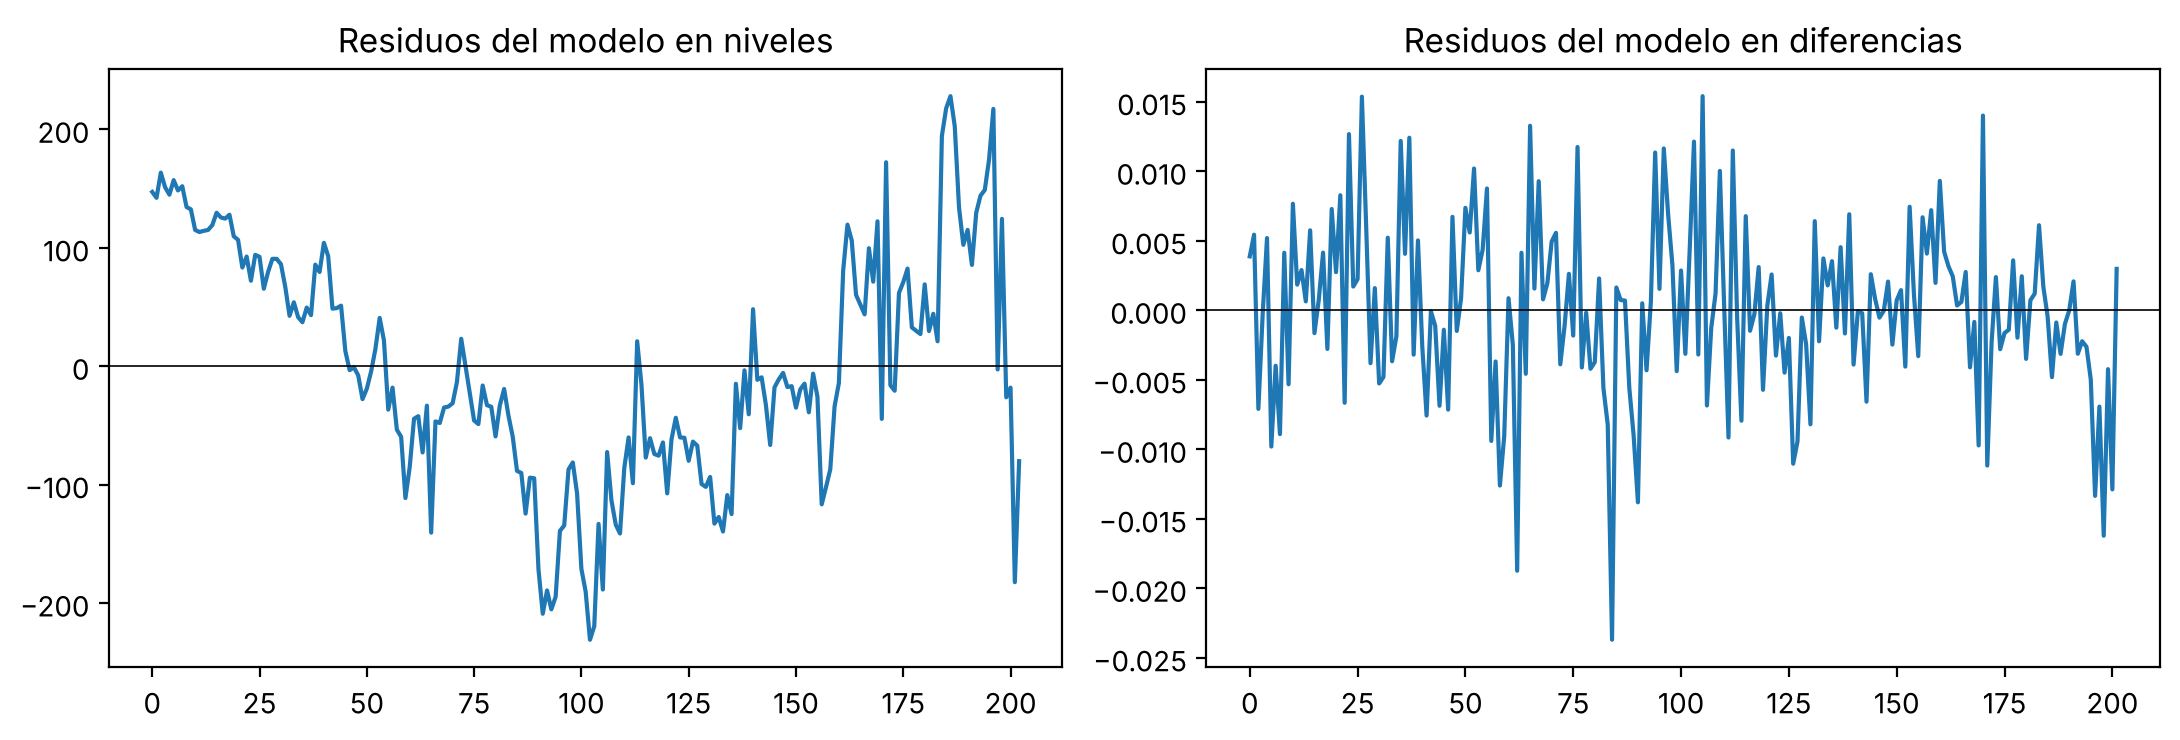

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(m1.resid.values); ax[0].set_title('Residuos del modelo en niveles'); ax[0].axhline(0, c='k', lw=.6)
ax[1].plot(m3.resid.values); ax[1].set_title('Residuos del modelo en diferencias'); ax[1].axhline(0, c='k', lw=.6)
plt.tight_layout(); plt.savefig('figura_residuos.png', dpi=130); plt.show()

In [7]:
resumen = pd.DataFrame({
  'Modelo': ['Niveles', 'Log-log', 'Diferencias de logs'],
  'Pendiente': [m1.params.iloc[1], m2.params.iloc[1], m3.params.iloc[1]],
  'R2': [m1.rsquared, m2.rsquared, m3.rsquared],
  'Durbin-Watson': [durbin_watson(m1.resid), durbin_watson(m2.resid), durbin_watson(m3.resid)]}).round(3)
resumen

,Modelo,Pendiente,R2,Durbin-Watson
0,Niveles,0.954,0.998,0.253
1,Log-log,1.032,0.998,0.188
2,Diferencias de logs,0.341,0.193,1.889


## 5. Conclusiones
- En niveles, la PMC estimada es alta y el ajuste parece casi perfecto, pero el Durbin-Watson revela autocorrelación fuerte en los residuos: los errores estándar y las pruebas *t* no son confiables.
- En primeras diferencias el $R^2$ cae a cerca de 0.19, la pendiente baja a cerca de 0.34 y el Durbin-Watson mejora a cerca de 1.9: gran parte del "ajuste perfecto" venía de la tendencia común de las series, no de una relación estable en el corto plazo.
- **Lección metodológica:** un $R^2$ alto no basta para validar un modelo con series de tiempo. Para estimar la función de consumo con rigor habría que probar estacionariedad (por ejemplo, pruebas de raíz unitaria) y cointegración.

**Limitaciones y siguientes pasos:** datos solo de EE. UU. hasta 2009; replicar con datos de México (INEGI) y agregar pruebas ADF y modelo de corrección de errores.